In [1]:
import pandas as pd

df = pd.read_csv("../res/Buenos Aires.csv")

In [2]:
print(df.shape) # check the size of the dataset
print(df.isna().sum()) # look at any possible NaN values

(145344, 16)
time                       0
temperature_2m             0
relative_humidity_2m       0
dew_point_2m               0
apparent_temperature       0
precipitation              0
weather_code               0
pressure_msl               0
surface_pressure           0
cloud_cover                0
vapour_pressure_deficit    0
wind_speed_10m             0
wind_direction_10m         0
wind_gusts_10m             0
is_day                     0
shortwave_radiation        0
dtype: int64


In [3]:
df.describe()

,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,weather_code,pressure_msl,surface_pressure,cloud_cover,vapour_pressure_deficit,wind_speed_10m,wind_direction_10m,wind_gusts_10m,is_day,shortwave_radiation
count,145344.000000,145344.000000,145344.000000,145344.000000,145344.000000,145344.000000,145344.000000,145344.000000,145344.000000,145344.000000,145344.000000,145344.000000,145344.000000,145344.000000,145344.000000
mean,17.505909,72.929677,12.184239,16.368124,0.116131,6.868663,1015.731018,1011.322639,46.087812,0.630919,15.642401,153.656319,28.095348,0.505766,201.684129
std,6.192710,15.325280,5.664872,8.022785,0.665940,16.487751,6.338654,6.255463,42.281481,0.554743,6.934872,104.227295,11.154225,0.499968,288.719809
min,-1.400000,15.000000,-7.800000,-5.300000,0.000000,0.000000,993.300000,989.200000,0.000000,0.000000,0.000000,1.000000,1.100000,0.000000,0.000000
25%,12.800000,63.000000,8.200000,10.200000,0.000000,0.000000,1011.400000,1007.000000,0.000000,0.250000,10.600000,68.000000,19.800000,0.000000,0.000000
50%,17.500000,75.000000,12.500000,16.200000,0.000000,1.000000,1015.500000,1011.100000,37.000000,0.460000,14.900000,130.000000,27.000000,1.000000,7.000000
75%,22.100000,85.000000,16.500000,22.400000,0.000000,3.000000,1019.800000,1015.300000,96.000000,0.830000,20.000000,232.000000,35.300000,1.000000,359.000000
max,38.900000,100.000000,27.300000,41.300000,29.000000,73.000000,1042.200000,1037.500000,100.000000,5.630000,59.100000,360.000000,95.800000,1.000000,1118.000000


## Plotting the data

Text(0, 0.5, '°C')

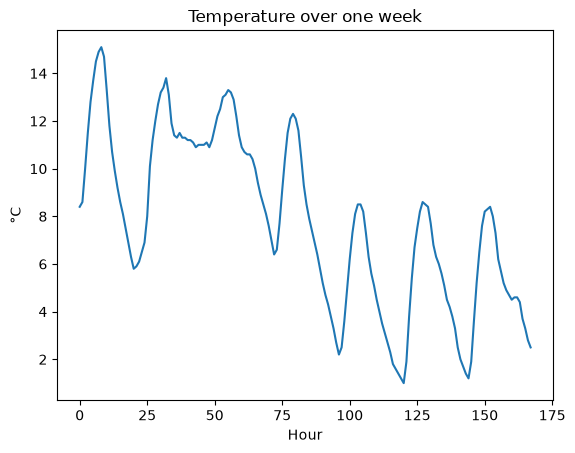

In [11]:
import matplotlib.pyplot as plt

week = df["temperature_2m"].iloc[5000:5168].reset_index(drop=True)

week.plot() # take a look at the temperature in a random week
plt.title("Temperature over one week")
plt.xlabel("Hour")
plt.ylabel("°C")

We can see very clearly that temperature follows a trend during the day and night cycles. Let's take a look at the bigger picture.

Text(0, 0.5, '°C')

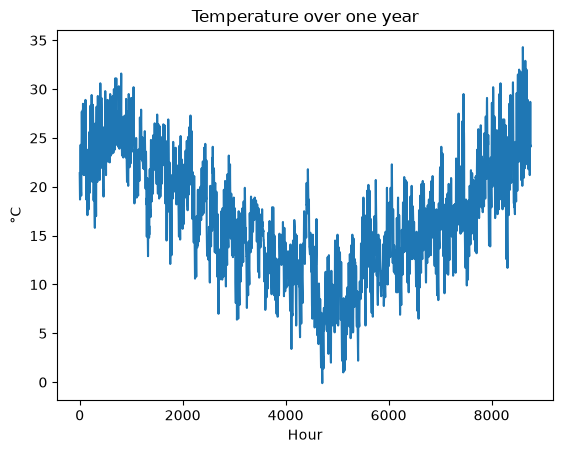

In [12]:
year = df["temperature_2m"].iloc[:8760].reset_index(drop=True)

year.plot()
plt.title("Temperature over one year")
plt.xlabel("Hour")
plt.ylabel("°C")

As we saw earlier in the weekly chart, temperature follows trends, now in the yearly chart we can see how it also does depending on the season.

## Let's analyze what features could we use to improve our model's performance

Text(0.5, 1.0, 'Average temperature of each hour')

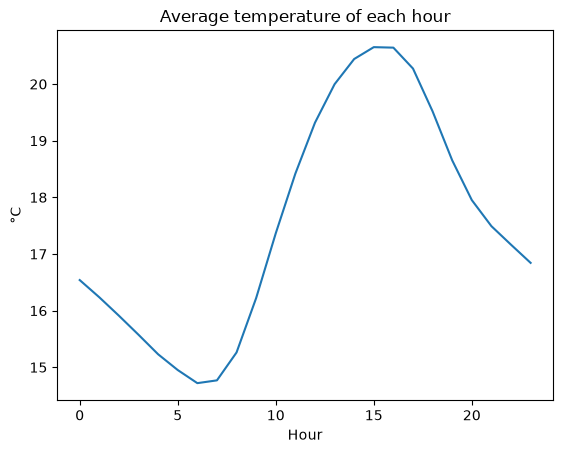

In [17]:
df["time"] = pd.to_datetime(df["time"])
df["hour"] = df["time"].dt.hour
df.groupby("hour")["temperature_2m"].mean().plot()
plt.xlabel("Hour")
plt.ylabel("°C")
plt.title("Average temperature of each hour")

We can notice that the average temperature around 6 AM is the lowest and at 4 PM is the highest. With an uptrend picking up at 6 AM and consolidating by 4 PM.

/tmp/ipykernel_28293/3763356890.py:4: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=["target"], inplace=True)


<Axes: >

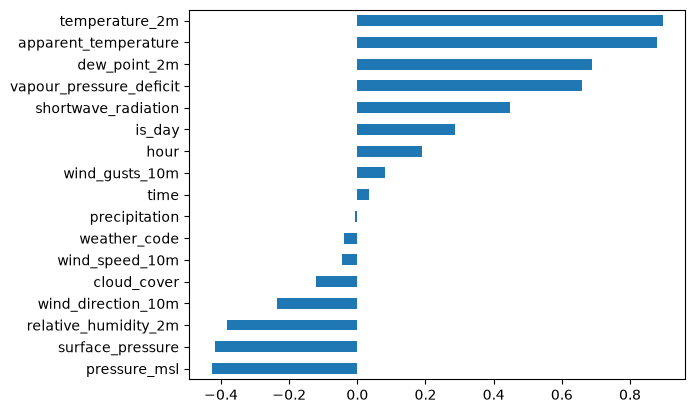

In [ ]:
df["target"] = df["temperature_2m"].shift(-24)
df.dropna(subset=["target"], inplace=True)
corr_m = df.corr()
corr_m["target"].drop("target").sort_values().plot(kind="barh")

The correlation matrix gave us very valuable information, this bar chart shows how every feature correlates with the target the model will be guessing in the future. Temperature and dew point are some of the features that best correlate with tomorrows temperature, if you think about it, it makes sense. Something to note is that a correlation close to 0 doesn't mean that feature is useless.